# Part 1 – Exploratory data analysis

In [44]:
import ast
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

DATA = 'data'

BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, MUTED, GRID = '#52514e', '#8a8984', '#e6e5e1'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#b9b8b1', 'axes.labelcolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': INK, 'ytick.color': INK, 'legend.frameon': False,
})

def note(ax, text, left=False):
    ax.margins(y=0.2)
    ax.text(0.02 if left else 0.98, 0.97, text, transform=ax.transAxes,
            ha='left' if left else 'right', va='top', fontsize=8.5, color=MUTED)

def money(x, _pos=None):
    for div, unit in [(1e9, 'B'), (1e6, 'M'), (1e3, 'K')]:
        if x >= div:
            return f'${x / div:g}{unit}'
    return f'${x:g}'

# Read-only helpers. Returns the parsed value, or None if the cell is empty or not of the expected type
def parse_list(x):
    try:
        v = ast.literal_eval(x)
    except (ValueError, SyntaxError):
        return None
    return v if isinstance(v, list) else None

def parse_dict(x):
    try:
        v = ast.literal_eval(x)
    except (ValueError, SyntaxError):
        return None
    return v if isinstance(v, dict) else None

In [45]:
movies_raw   = pd.read_csv(f'{DATA}/movies_metadata.csv', low_memory=False)
credits_raw  = pd.read_csv(f'{DATA}/credits.csv')
keywords_raw = pd.read_csv(f'{DATA}/keywords.csv')
links        = pd.read_csv(f'{DATA}/links_small.csv', dtype={'imdbId': str})
links_full   = pd.read_csv(f'{DATA}/links.csv', dtype={'imdbId': str})
ratings      = pd.read_csv(f'{DATA}/ratings.csv')

pd.DataFrame(
    {'rows': [len(d) for d in (movies_raw, credits_raw, keywords_raw, links, ratings)],
     'columns': [d.shape[1] for d in (movies_raw, credits_raw, keywords_raw, links, ratings)]},
    index=['movies_metadata', 'credits', 'keywords', 'links_small', 'ratings'])

,rows,columns
movies_metadata,45466,24
credits,45476,3
keywords,46419,2
links_small,9125,3
ratings,26024289,4


## Movies: overview

In [46]:
display(movies_raw.head(3))
movies_raw.dtypes

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,popularity,poster_path,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",21.946943,/rhIRbceoE9lR4veEXuwCC2wARtG.jpg,"[{'name': 'Pixar Animation Studios', 'id': 3}]","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,17.015539,/vzmL6fP7aPKNKPRTFnZmiUfciyV.jpg,"[{'name': 'TriStar Pictures', 'id': 559}, {'na...","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,11.7129,/6ksm1sjKMFLbO7UY2i6G1ju9SML.jpg,"[{'name': 'Warner Bros.', 'id': 6194}, {'name'...","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0


adult                     object
belongs_to_collection     object
budget                    object
genres                    object
homepage                  object
id                        object
imdb_id                   object
original_language         object
original_title            object
overview                  object
popularity                object
poster_path               object
production_companies      object
production_countries      object
release_date              object
revenue                  float64
runtime                  float64
spoken_languages          object
status                    object
tagline                   object
title                     object
video                     object
vote_average             float64
vote_count               float64
dtype: object

## Movies: broken rows

In [47]:
bad_idx = movies_raw.index[~movies_raw['id'].astype(str).str.fullmatch(r'\d+')]
print('Rows with a non-numeric id:', len(bad_idx))
display(movies_raw.loc[bad_idx, ['adult', 'budget', 'id', 'title']])
print('The row above each one (cut short):')
display(movies_raw.loc[bad_idx - 1, ['id', 'original_title', 'title', 'release_date', 'vote_count']])

Rows with a non-numeric id: 3


,adult,budget,id,title
19730,- Written by Ørnås,/ff9qCepilowshEtG2GYWwzt2bs4.jpg,1997-08-20,NaN
29503,Rune Balot goes to a casino connected to the ...,/zV8bHuSL6WXoD6FWogP9j4x80bL.jpg,2012-09-29,NaN
35587,Avalanche Sharks tells the story of a bikini ...,/zaSf5OG7V8X8gqFvly88zDdRm46.jpg,2014-01-01,NaN


The row above each one (cut short):


,id,original_title,title,release_date,vote_count
19729,82663,Midnight Man,NaN,NaN,NaN
29502,122662,マルドゥック・スクランブル 排気,NaN,NaN,NaN
35586,249260,Avalanche Sharks,NaN,NaN,NaN


## Movies: duplicates

In [74]:
id_num = pd.to_numeric(movies_raw['id'], errors='coerce')
invalid_id = id_num.isna()

print('Rows with invalid IDs:', invalid_id.sum())
movies_raw = movies_raw.loc[~invalid_id].copy()
movies_raw['id'] = id_num.loc[~invalid_id].astype('int64')

dup_mask = movies_raw['id'].duplicated(keep=False)
print('Rows sharing an id with another row:', dup_mask.sum())
print('Distinct duplicated ids:', movies_raw.loc[dup_mask, 'id'].nunique())
print('Exact duplicate rows:', movies_raw.duplicated().sum())

movies_raw.loc[dup_mask].sort_values('id')[
    ['id', 'title', 'release_date', 'popularity', 'vote_count']
].head(10)
movies_raw['id'] = movies_raw['id'].astype(int)


movies_raw.loc[dup_mask].sort_values('id')[['id', 'title', 'release_date', 'popularity', 'vote_count']].head(10)

Rows with invalid IDs: 0
Rows sharing an id with another row: 59
Distinct duplicated ids: 29
Exact duplicate rows: 17


,id,title,release_date,popularity,vote_count
5865,4912,Confessions of a Dangerous Mind,2002-12-30,11.331072,281.0
33826,4912,Confessions of a Dangerous Mind,2002-12-30,7.645827,281.0
9165,5511,Le Samouraï,1967-10-25,9.091288,187.0
7345,5511,Le Samouraï,1967-10-25,9.091288,187.0
44821,10991,Pokémon: Spell of the Unknown,2000-07-08,6.480376,144.0
4114,10991,Pokémon: Spell of the Unknown,2000-07-08,10.264597,143.0
14012,11115,Deal,2008-01-29,6.880365,22.0
24844,11115,Deal,2008-01-29,6.880365,22.0
44826,12600,Pokémon 4Ever: Celebi - Voice of the Forest,2001-07-06,6.080108,82.0
5535,12600,Pokémon 4Ever: Celebi - Voice of the Forest,2001-07-06,7.072301,82.0


## Movies: nested columns

In [49]:
LIST_COLS = ['genres', 'production_companies', 'production_countries', 'spoken_languages']

# Parsed copies used for analysis only
nested = pd.DataFrame({col: movies_raw[col].apply(parse_list) for col in LIST_COLS})
nested['belongs_to_collection'] = movies_raw['belongs_to_collection'].apply(parse_dict)

print('Non-empty cells that could not be parsed:')
for col in nested.columns:
    print(f'  {col:22s} {(movies_raw[col].notna() & nested[col].isna()).sum()}')
nested[LIST_COLS].head(3)

Non-empty cells that could not be parsed:
  genres                 0
  production_companies   3
  production_countries   3
  spoken_languages       0
  belongs_to_collection  3


,genres,production_companies,production_countries,spoken_languages
0,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...","[{'name': 'Pixar Animation Studios', 'id': 3}]","[{'iso_3166_1': 'US', 'name': 'United States o...","[{'iso_639_1': 'en', 'name': 'English'}]"
1,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...","[{'name': 'TriStar Pictures', 'id': 559}, {'na...","[{'iso_3166_1': 'US', 'name': 'United States o...","[{'iso_639_1': 'en', 'name': 'English'}, {'iso..."
2,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...","[{'name': 'Warner Bros.', 'id': 6194}, {'name'...","[{'iso_3166_1': 'US', 'name': 'United States o...","[{'iso_639_1': 'en', 'name': 'English'}]"


## Movies: missing and unknown values

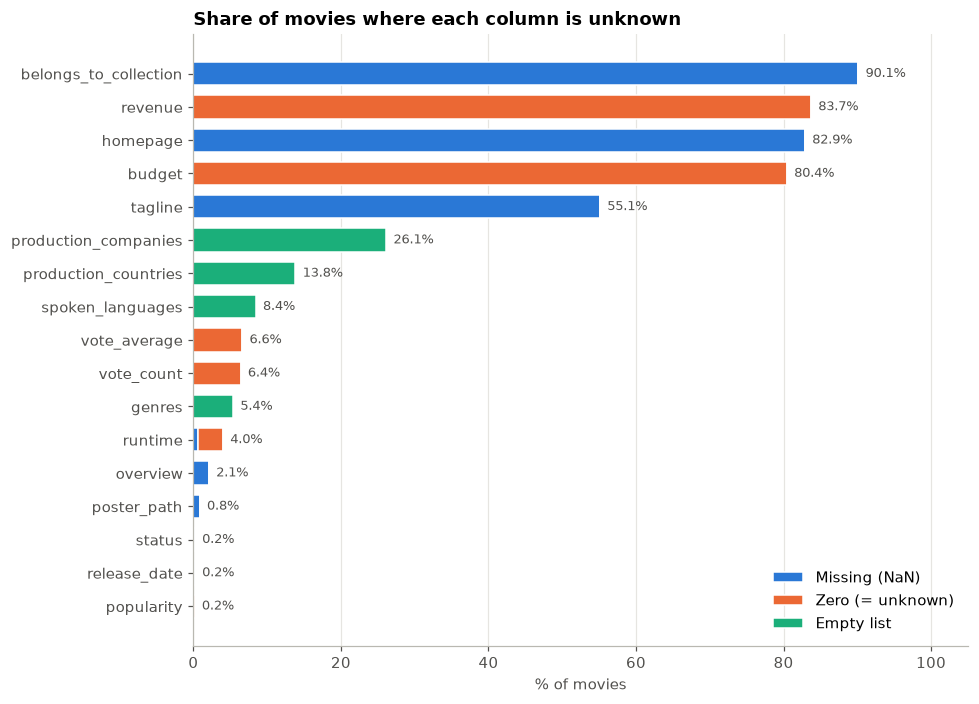

In [50]:
NUM_COLS = ['budget', 'revenue', 'runtime', 'vote_count', 'vote_average', 'popularity']
num = pd.DataFrame({c: pd.to_numeric(movies_raw[c], errors='coerce') for c in NUM_COLS})

unknown = pd.DataFrame({
    'Missing (NaN)': movies_raw.isna().mean() * 100,
    'Zero (= unknown)': (num == 0).mean() * 100,
    'Empty list': pd.Series({c: nested[c].apply(lambda v: v == []).mean() * 100 for c in LIST_COLS}),
}).fillna(0)
unknown['total'] = unknown.sum(axis=1)
unknown = unknown[unknown['total'] > 0.05].sort_values('total')

fig, ax = plt.subplots(figsize=(9, 6.5))
left = np.zeros(len(unknown))
for name, color in [('Missing (NaN)', BLUE), ('Zero (= unknown)', ORANGE), ('Empty list', AQUA)]:
    ax.barh(unknown.index, unknown[name], left=left, color=color, label=name, height=0.7,
            edgecolor='white', linewidth=1)
    left += unknown[name].values
for y, total in enumerate(unknown['total']):
    ax.text(total + 1, y, f'{total:.1f}%', va='center', fontsize=8.5, color=INK)
ax.set_xlim(0, 105)
ax.set_xlabel('% of movies')
ax.grid(axis='y', visible=False)
ax.set_title('Share of movies where each column is unknown')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

## Movies: numeric attributes

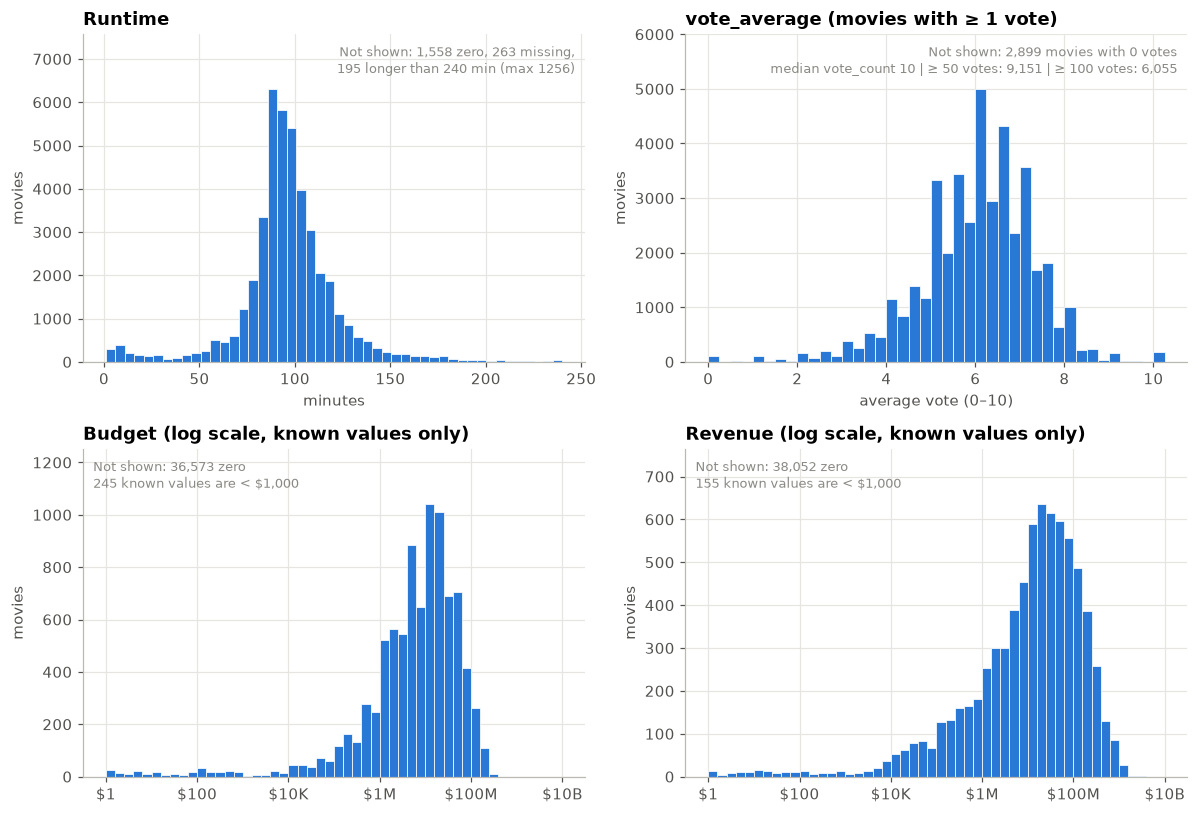

In [51]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))

rt = num['runtime']
ax = axes[0, 0]
ax.hist(rt[(rt > 0) & (rt <= 240)], bins=48, color=BLUE, edgecolor='white', linewidth=0.5)
ax.set_title('Runtime'); ax.set_xlabel('minutes'); ax.set_ylabel('movies')
note(ax, f'Not shown: {(rt == 0).sum():,} zero, {rt.isna().sum():,} missing,\n{(rt > 240).sum():,} longer than 240 min (max {rt.max():.0f})')

ax = axes[0, 1]
voted = num.loc[num['vote_count'] > 0, 'vote_average']
ax.hist(voted, bins=np.arange(0, 10.5, 0.25), color=BLUE, edgecolor='white', linewidth=0.5)
ax.set_title('vote_average (movies with ≥ 1 vote)'); ax.set_xlabel('average vote (0–10)'); ax.set_ylabel('movies')
vc = num['vote_count']
note(ax, f'Not shown: {(vc == 0).sum():,} movies with 0 votes\n'
         f'median vote_count {vc.median():.0f} | ≥ 50 votes: {(vc >= 50).sum():,} | ≥ 100 votes: {(vc >= 100).sum():,}')

bins = np.logspace(0, 10, 51)
for ax, col in [(axes[1, 0], 'budget'), (axes[1, 1], 'revenue')]:
    s = num[col]
    ax.hist(s[s > 0], bins=bins, color=BLUE, edgecolor='white', linewidth=0.5)
    ax.set_xscale('log'); ax.xaxis.set_major_formatter(FuncFormatter(money))
    ax.set_title(f'{col.capitalize()} (log scale, known values only)'); ax.set_ylabel('movies')
    note(ax, f'Not shown: {(s == 0).sum():,} zero\n{((s > 0) & (s < 1000)).sum():,} known values are < $1,000', left=True)

plt.tight_layout(); plt.show()

In [52]:
tiny = lambda s: (s > 0) & (s < 1000)
print('Budgets between 1 and 999 USD:', tiny(num['budget']).sum())
print('Revenues between 1 and 999 USD:', tiny(num['revenue']).sum())
num.assign(title=movies_raw['title'],
           year=pd.to_datetime(movies_raw['release_date'], errors='coerce').dt.year.astype('Int64')
           ).loc[tiny(num['revenue']), ['title', 'year', 'budget', 'revenue', 'vote_count']
           ].sort_values('vote_count', ascending=False).head(8)

Budgets between 1 and 999 USD: 245
Revenues between 1 and 999 USD: 155


,title,year,budget,revenue,vote_count
9449,Ong-Bak: The Thai Warrior,2003,0.0,15.0,556.0
6076,Irreversible,2002,0.0,792.0,550.0
11918,Death at a Funeral,2007,9000000.0,46.0,508.0
21597,I Spit on Your Grave 2,2013,0.0,809.0,281.0
44956,2:22,2017,0.0,422.0,277.0
13480,Dr. Horrible's Sing-Along Blog,2008,200000.0,3.0,236.0
5541,The 51st State,2001,28.0,14.0,173.0
922,East of Eden,1955,1.0,5.0,163.0


In [53]:
runtime_data = movies_raw.assign(
    runtime=num['runtime'],
    year=pd.to_datetime(movies_raw['release_date'], errors='coerce')
           .dt.year.astype('Int64')
)

print('Runtime > 300 min:', (runtime_data['runtime'] > 300).sum())
runtime_data.nlargest(5, 'runtime')[['title', 'year', 'runtime', 'genres']]

Runtime > 300 min: 108


,title,year,runtime,genres
24178,Centennial,1978,1256.0,"[{'id': 18, 'name': 'Drama'}, {'id': 36, 'name..."
19965,Jazz,2001,1140.0,"[{'id': 99, 'name': 'Documentary'}]"
40938,Baseball,1994,1140.0,"[{'id': 99, 'name': 'Documentary'}]"
13767,Berlin Alexanderplatz,1980,931.0,"[{'id': 18, 'name': 'Drama'}]"
13953,Heimat: A Chronicle of Germany,1984,925.0,"[{'id': 18, 'name': 'Drama'}, {'id': 36, 'name..."


In [54]:
no_votes = num['vote_count'].eq(0)
n = len(num)

print(f'vote_count == 0: {no_votes.sum() / n * 100:.2f}%')
print('vote_average when vote_count == 0:',
    num.loc[no_votes, 'vote_average'].value_counts().to_dict())
print('vote_average == 0 with votes > 0:',
    ((num['vote_average'] == 0) & (num['vote_count'] > 0)).sum())

vote_count == 0: 6.38%
vote_average when vote_count == 0: {0.0: 2899}
vote_average == 0 with votes > 0: 99


## Movies: Impact of missing budget

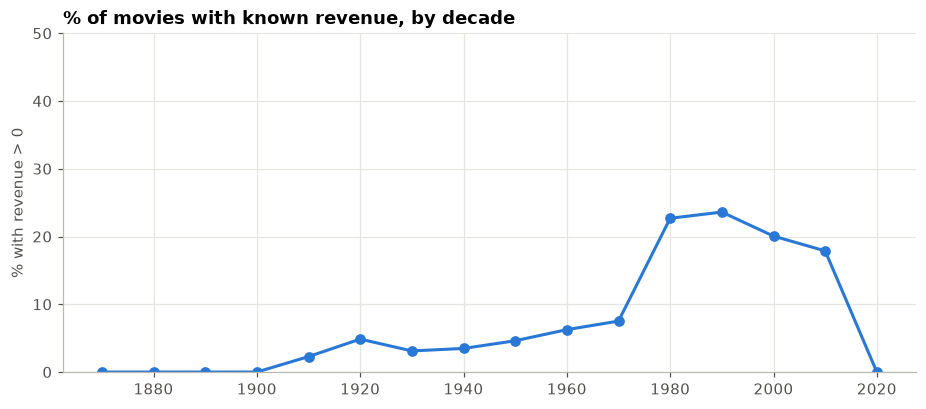

In [55]:
release = pd.to_datetime(movies_raw['release_date'], errors='coerce')
decade = (release.dt.year // 10 * 10).astype('Int64')
has_rev = num['revenue'] > 0

by_decade = (
    pd.DataFrame({'decade': decade, 'revenue': num['revenue']})
    .dropna(subset=['decade'])
    .groupby('decade')
    .agg(
        movies=('revenue', 'size'),
        revenue_known=('revenue', lambda s: s.gt(0).mean() * 100),
    )
)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(by_decade.index.astype(int), by_decade['revenue_known'],
        color=BLUE, lw=2, marker='o', ms=6)
ax.set_title('% of movies with known revenue, by decade')
ax.set_ylabel('% with revenue > 0')
ax.set_ylim(0, 50)
plt.show()



In [56]:
en = movies_raw['original_language'] == 'en'
print('Revenue known, English-language:    ', f"{100 * has_rev[en].mean():.1f} %")
print('Revenue known, non-English-language:', f"{100 * has_rev[~en].mean():.1f} %")

Revenue known, English-language:     19.7 %
Revenue known, non-English-language: 8.0 %


## Movies: small budgets and revenues
Known budgets and revenues on a log scale. Values under $1,000 (orange) are not realistic for a movie.

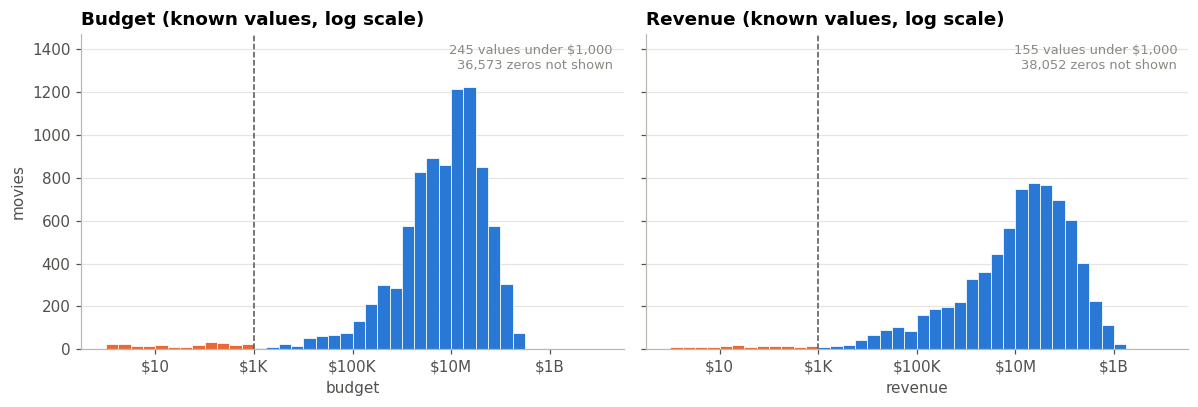

In [9]:
bins = np.logspace(0, 10, 41)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, col in zip(axes, ['budget', 'revenue']):
    s = num[col]
    s = s[s > 0]
    counts, edges = np.histogram(s, bins=bins)
    colors = [ORANGE if right <= 1000 else BLUE for right in edges[1:]]
    ax.bar(edges[:-1], counts, width=np.diff(edges), align='edge', color=colors, edgecolor='white', linewidth=0.5)
    ax.axvline(1000, color=INK, linestyle='--', linewidth=1)
    ax.set_xscale('log'); ax.xaxis.set_major_formatter(FuncFormatter(money))
    ax.set_title(f'{col.capitalize()} (known values, log scale)'); ax.set_xlabel(col)
    ax.grid(axis='x', visible=False)
    note(ax, f'{(s < 1000).sum():,} values under $1,000\n{(num[col] == 0).sum():,} zeros not shown')
axes[0].set_ylabel('movies')

plt.tight_layout(); plt.show()

## Movies: release dates

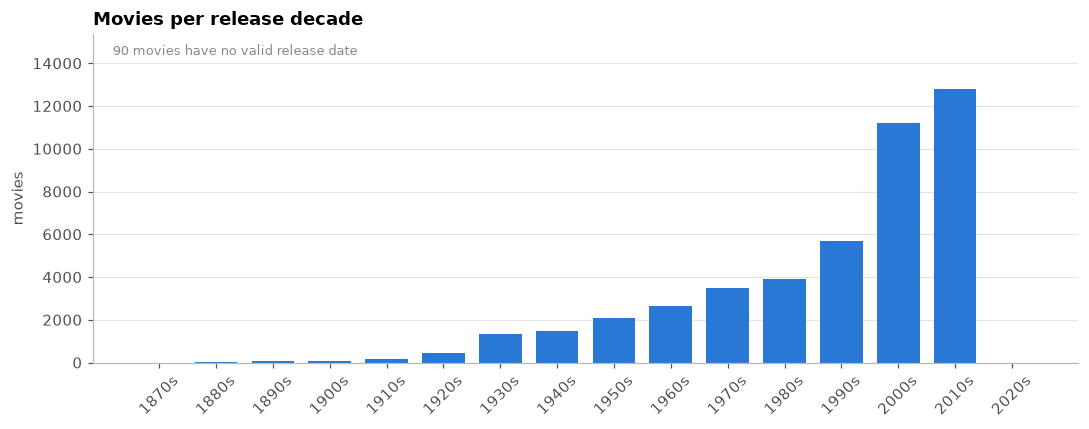

Date range: 1874-12-09 → 2020-12-16


In [10]:
release = pd.to_datetime(movies_raw['release_date'], errors='coerce')
decades = (release.dt.year // 10 * 10).dropna().astype(int).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar([f"{d}s" for d in decades.index], decades.values, color=BLUE, width=0.75)
ax.set_title('Movies per release decade'); ax.set_ylabel('movies')
ax.tick_params(axis='x', rotation=45); ax.grid(axis='x', visible=False)
note(ax, f'{release.isna().sum()} movies have no valid release date', left=True)
plt.tight_layout(); plt.show()
print('Date range:', release.min().date(), '→', release.max().date())

## Movies: genres, languages, status and collections

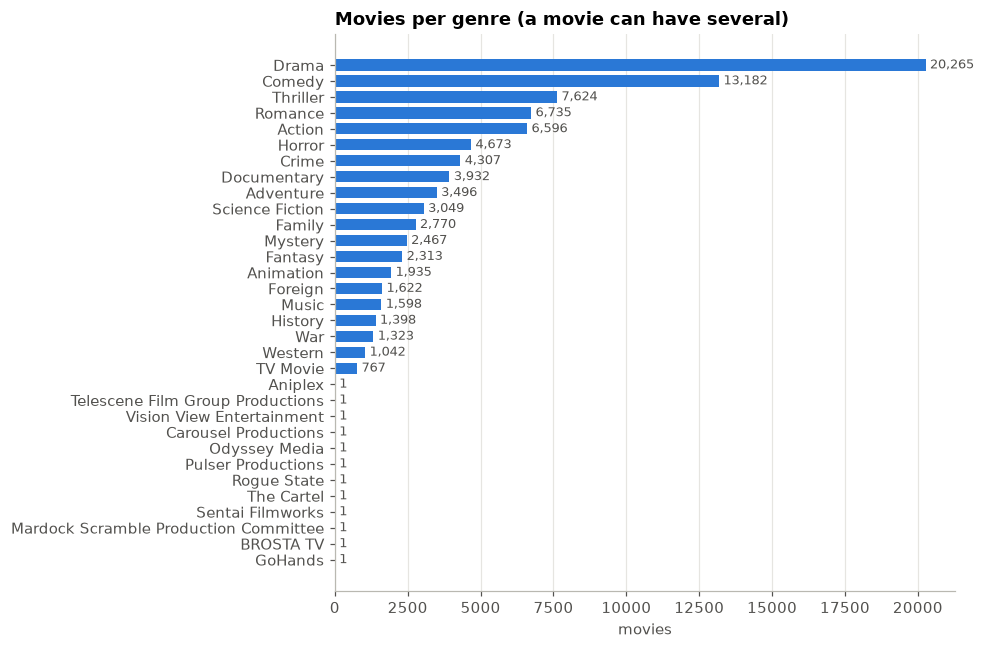

Distinct genres: 32 | movies without genre: 2442


In [58]:
genre_counts = pd.Series([g['name'] for gl in nested['genres'].dropna() for g in gl]).value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(genre_counts.index, genre_counts.values, color=BLUE, height=0.7)
for y, v in enumerate(genre_counts.values):
    ax.text(v + 150, y, f'{v:,}', va='center', fontsize=8.5, color=INK)
ax.set_title('Movies per genre (a movie can have several)'); ax.set_xlabel('movies')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

print('Distinct genres:', genre_counts.size, '| movies without genre:', (nested['genres'].apply(lambda v: v == [])).sum())

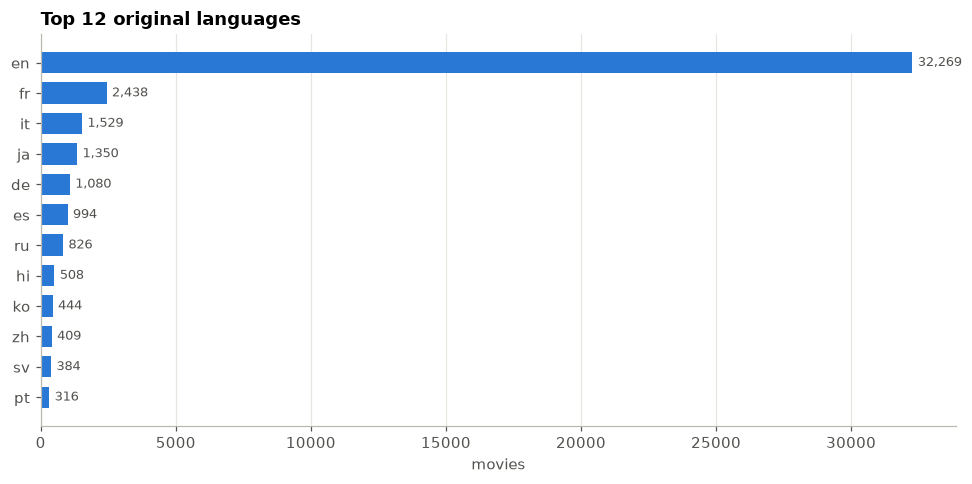

Non-English movies with US as a production country: 457


In [59]:
lang = movies_raw['original_language'].value_counts().head(12).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(lang.index, lang.values, color=BLUE, height=0.7)
for y, v in enumerate(lang.values):
    ax.text(v + 200, y, f'{v:,}', va='center', fontsize=8.5, color=INK)
ax.set_title('Top 12 original languages'); ax.set_xlabel('movies'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

us = nested['production_countries'].apply(lambda cs: any(c.get('iso_3166_1') == 'US' for c in (cs or [])))
print('Non-English movies with US as a production country:', ((movies_raw['original_language'] != 'en') & us).sum())

In [75]:
coll_names = nested['belongs_to_collection'].dropna().apply(lambda d: d['name'])
sizes = coll_names.value_counts()
print(f'Movies in a collection: {len(coll_names):,} | distinct collections: {sizes.size:,} | collections with ≥ 3 movies: {(sizes >= 3).sum()}')
print('Largest collections:'); print(sizes.head(5).to_string())


Movies in a collection: 4,491 | distinct collections: 1,695 | collections with ≥ 3 movies: 628
Largest collections:
belongs_to_collection
The Bowery Boys                  29
Totò Collection                  27
James Bond Collection            26
Zatôichi: The Blind Swordsman    26
The Carry On Collection          25


## Credits: overview

In [61]:
print('Rows:', len(credits_raw), '| duplicated ids:', credits_raw['id'].duplicated().sum(),
      '| exact duplicate rows:', credits_raw.duplicated().sum())

# Parsed copies used for analysis only
cast = credits_raw['cast'].apply(parse_list)
crew = credits_raw['crew'].apply(parse_list)

print('Unparsable cast:', cast.isna().sum(), '| unparsable crew:', crew.isna().sum())
print('Empty cast:', (cast.str.len() == 0).sum(), '| empty crew:', (crew.str.len() == 0).sum(),
      '| both empty:', ((cast.str.len() == 0) & (crew.str.len() == 0)).sum())
print('\nFields in a cast entry:', list(cast.iloc[0][0].keys()))
print('Fields in a crew entry:', list(crew.iloc[0][0].keys()))

Rows: 45476 | duplicated ids: 44 | exact duplicate rows: 37
Unparsable cast: 0 | unparsable crew: 0
Empty cast: 2418 | empty crew: 771 | both empty: 421

Fields in a cast entry: ['cast_id', 'character', 'credit_id', 'gender', 'id', 'name', 'order', 'profile_path']
Fields in a crew entry: ['credit_id', 'department', 'gender', 'id', 'job', 'name', 'profile_path']


## Credits: duplicates

In [62]:
# Same check as for movies. Ignore exact copies, show ids that still have different rows
dedup_c = credits_raw.drop_duplicates()
conflict_c = dedup_c[dedup_c['id'].duplicated(keep=False)].sort_values('id')
diff_cols_c = [col for col in conflict_c.columns
               if conflict_c.groupby('id')[col].nunique(dropna=False).gt(1).any()]
print('ids with differing rows:', conflict_c['id'].nunique(), '| rows:', len(conflict_c))
print('Columns that differ:', diff_cols_c)

# cast/crew are long lists, so summarise them instead of printing the raw text
as_set = lambda people: sorted(tuple(sorted(p.items())) for p in people)
titles = movies_raw.assign(id=pd.to_numeric(movies_raw['id'], errors='coerce')).drop_duplicates('id').set_index('id')['title']
view = pd.DataFrame({
    'id': conflict_c['id'],
    'title': conflict_c['id'].map(titles),
    'cast size': cast[conflict_c.index].str.len(),
    'crew size': crew[conflict_c.index].str.len(),
    'crew (sorted)': crew[conflict_c.index].apply(as_set),
})
view['same crew, other order'] = view.groupby('id')['crew (sorted)'].transform(lambda s: s.iloc[0] == s.iloc[-1])
display(view.drop(columns='crew (sorted)'))

ids with differing rows: 7 | rows: 14
Columns that differ: ['crew']


,id,title,cast size,crew size,"same crew, other order"
5865,4912,Confessions of a Dangerous Mind,26,16,True
33838,4912,Confessions of a Dangerous Mind,26,16,True
26638,69234,The Phantom of the Opera,7,15,True
9576,69234,The Phantom of the Opera,7,15,True
38882,99080,The Viking,5,4,True
16167,99080,The Viking,5,4,True
23533,110428,Camille Claudel 1915,14,17,True
4356,110428,Camille Claudel 1915,14,17,True
30013,132641,Wife,19,12,True
838,132641,Wife,19,12,True


## Credits: gender

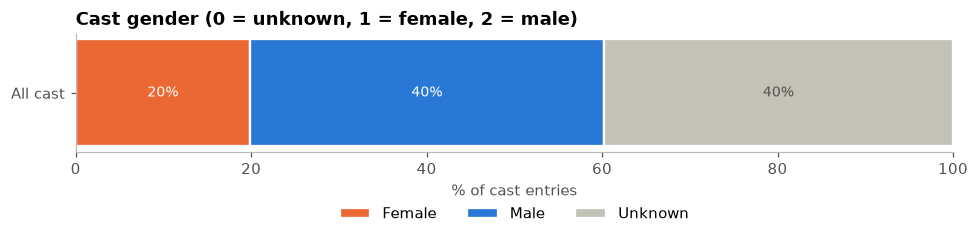

In [63]:
all_cast = [p for cl in cast for p in cl]
labels = {1: 'Female', 2: 'Male', 0: 'Unknown'}

shares = pd.DataFrame({
    'All cast': pd.Series(Counter(p['gender'] for p in all_cast)),
}).T[[1, 2, 0]]
shares = shares.div(shares.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9, 2.6))
left = np.zeros(len(shares))
for g, color in zip([1, 2, 0], [ORANGE, BLUE, '#c3c2b7']):
    ax.barh(shares.index, shares[g], left=left, color=color, label=labels[g], height=0.6, edgecolor='white', linewidth=1.5)
    for y, (l, v) in enumerate(zip(left, shares[g])):
        ax.text(l + v / 2, y, f'{v:.0f}%', ha='center', va='center', fontsize=9, color='white' if g else INK)
    left += shares[g].values
ax.set_xlim(0, 100); ax.set_xlabel('% of cast entries'); ax.grid(visible=False)
ax.set_title('Cast gender (0 = unknown, 1 = female, 2 = male)')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.35))
plt.tight_layout(); plt.show()

## Credits: data quality

In [64]:
n_dup_actor = sum(len({p['id'] for p in cl}) < len(cl) for cl in cast)
directors = crew.apply(lambda cl: [p for p in cl if p['job'] == 'Director'])
n_dir = directors.str.len()
n_dir_dup = sum(len({p['id'] for p in d}) < len(d) for d in directors)
order_not_zero = sum(min(p['order'] for p in cl) != 0 for cl in cast if cl)

names = {}
for p in all_cast:
    names.setdefault(p['name'], set()).add(p['id'])

pd.DataFrame({'value': [
    n_dup_actor, (n_dir == 0).sum(), (n_dir > 1).sum(), n_dir_dup, order_not_zero,
    len({p['id'] for p in all_cast}), sum(len(v) > 1 for v in names.values()),
]}, index=[
    'Movies where the same actor appears twice in the cast',
    'Movies with no director',
    'Movies with more than one director',
    'Movies where the same director is listed twice',
    'Movies whose cast "order" does not start at 0',
    'Distinct actors (by person id)',
    'Actor names shared by more than one person id',
])

,value
Movies where the same actor appears twice in the cast,953
Movies with no director,887
Movies with more than one director,3200
Movies where the same director is listed twice,0
"Movies whose cast ""order"" does not start at 0",6319
Distinct actors (by person id),206158
Actor names shared by more than one person id,3053


## Keywords: duplicates

In [65]:
print('Rows:', len(keywords_raw), '| duplicated ids:', keywords_raw['id'].duplicated().sum(),
      '| exact duplicate rows:', keywords_raw.duplicated().sum())

# Same check as for movies and credits. Ignore exact copies, show IDs that still have different rows
dedup_k = keywords_raw.drop_duplicates()
conflict_k = dedup_k[dedup_k['id'].duplicated(keep=False)]
print('ids with differing rows:', conflict_k['id'].nunique())

# How often the duplicated IDs repeat, with a few examples
dup_k = keywords_raw[keywords_raw['id'].duplicated(keep=False)]
copies = dup_k['id'].value_counts()
print('Times a duplicated id appears:', copies.value_counts().sort_index().to_dict())
print('Duplicated ids with no keywords:', (dup_k.drop_duplicates('id')['keywords'] == '[]').sum())
display(dup_k.sort_values('id').head(6))

Rows: 46419 | duplicated ids: 987 | exact duplicate rows: 987
ids with differing rows: 0
Times a duplicated id appears: {2: 983, 3: 2}
Duplicated ids with no keywords: 453


,id,keywords
37095,1998,"[{'id': 417, 'name': 'corruption'}, {'id': 612..."
36138,1998,"[{'id': 417, 'name': 'corruption'}, {'id': 612..."
36822,3025,"[{'id': 212, 'name': 'london england'}, {'id':..."
35865,3025,"[{'id': 212, 'name': 'london england'}, {'id':..."
35999,3692,"[{'id': 470, 'name': 'spy'}, {'id': 591, 'name..."
36956,3692,"[{'id': 470, 'name': 'spy'}, {'id': 591, 'name..."


## Duplicates in all files
Extra rows per file, split into exact copies and rows that share an id but have different values.

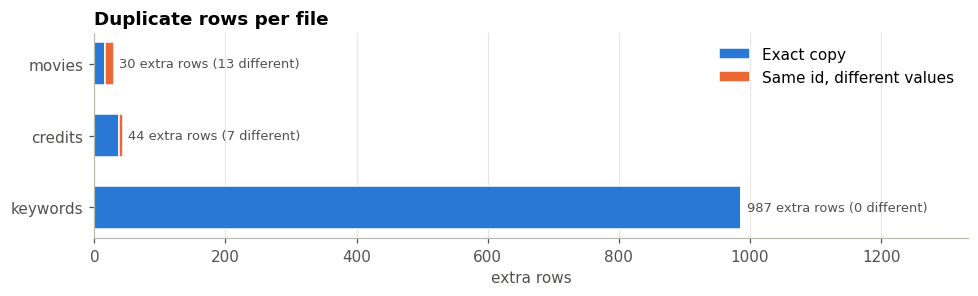

,Exact copy,"Same id, different values"
keywords,987,0
credits,37,7
movies,17,13


In [19]:
dups = pd.DataFrame({
    'Exact copy': [d.duplicated().sum() for d in (movies_raw, credits_raw, keywords_raw)],
    'Same id, different values': [d.drop_duplicates()['id'].duplicated().sum() for d in (movies_raw, credits_raw, keywords_raw)],
}, index=['movies', 'credits', 'keywords']).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 2.8))
left = np.zeros(len(dups))
for name, color in [('Exact copy', BLUE), ('Same id, different values', ORANGE)]:
    ax.barh(dups.index, dups[name], left=left, color=color, label=name, height=0.6, edgecolor='white', linewidth=1)
    left += dups[name].values
for y, (total, diff) in enumerate(zip(left, dups['Same id, different values'])):
    ax.text(total + 8, y, f'{int(total):,} extra rows ({diff} different)', va='center', fontsize=8.5, color=INK)
ax.set_xlim(0, left.max() * 1.35)
ax.set_title('Duplicate rows per file'); ax.set_xlabel('extra rows')
ax.grid(axis='y', visible=False); ax.legend(loc='upper right')
plt.tight_layout(); plt.show()
dups

## Joins between files

In [66]:
movie_ids = set(pd.to_numeric(movies_raw['id'], errors='coerce').dropna().astype(int))
pd.DataFrame({
    'ids not found in movies': [len(set(credits_raw['id']) - movie_ids), len(set(keywords_raw['id']) - movie_ids)],
    'movies without a row here': [len(movie_ids - set(credits_raw['id'])), len(movie_ids - set(keywords_raw['id']))],
}, index=['credits', 'keywords'])

,ids not found in movies,movies without a row here
credits,0,1
keywords,0,1


## Links

In [67]:
for name, df in [('links_small', links), ('links (full)', links_full)]:
    t = df['tmdbId'].dropna().astype(int)
    print(f'{name:13s} rows={len(df):6,} | missing tmdbId={df["tmdbId"].isna().sum():4} | '
          f'duplicated tmdbId={t.duplicated().sum():3} | tmdbId not in movies={(~t.isin(movie_ids)).sum():4}')

links_small   rows= 9,125 | missing tmdbId=  13 | duplicated tmdbId=  0 | tmdbId not in movies=  30
links (full)  rows=45,843 | missing tmdbId= 219 | duplicated tmdbId= 30 | tmdbId not in movies= 161


## Ratings

In [68]:
print('Missing values:', ratings.isna().sum().to_dict())
print('Same user rating the same movie twice:', ratings.duplicated(['userId', 'movieId']).sum())
print('Users:', ratings['userId'].nunique(), '| movies:', ratings['movieId'].nunique())
ts = pd.to_datetime(ratings['timestamp'], unit='s')
print('Time range:', ts.min(), '→', ts.max())

Missing values: {'userId': 0, 'movieId': 0, 'rating': 0, 'timestamp': 0}
Same user rating the same movie twice: 0
Users: 270896 | movies: 45115
Time range: 1995-01-09 11:46:44 → 2017-08-04 06:57:50


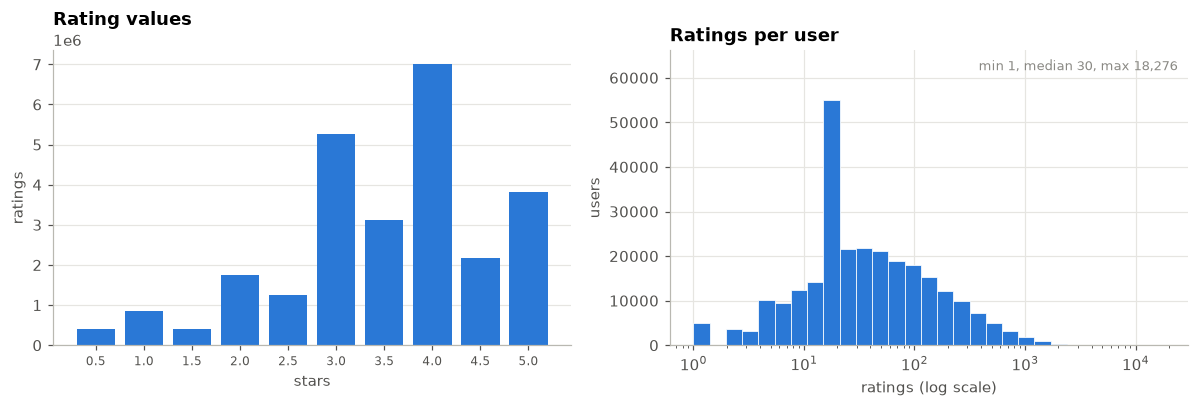

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

ax = axes[0]
vc = ratings['rating'].value_counts().sort_index()
ax.bar(vc.index, vc.values, width=0.4, color=BLUE)
ax.set_xticks(vc.index); ax.tick_params(axis='x', labelsize=8)
ax.set_title('Rating values'); ax.set_xlabel('stars'); ax.set_ylabel('ratings'); ax.grid(axis='x', visible=False)

ax = axes[1]
per_user = ratings.groupby('userId').size()
ax.hist(per_user, bins=np.logspace(np.log10(per_user.min()), np.log10(per_user.max()), 30), color=BLUE, edgecolor='white', linewidth=0.5)
ax.set_xscale('log'); ax.set_title('Ratings per user'); ax.set_xlabel('ratings (log scale)'); ax.set_ylabel('users')
note(ax, f'min {per_user.min()}, median {per_user.median():.0f}, max {per_user.max():,}')

plt.tight_layout(); plt.show()

## Ratings: matching to movies

In [70]:
to_tmdb = dict(zip(links['movieId'], links['tmdbId']))
tmdb = ratings['movieId'].map(to_tmdb)
in_links = ratings['movieId'].isin(links['movieId'])
has_tmdb = tmdb.notna()
in_movies = has_tmdb & tmdb.fillna(-1).astype(int).isin(movie_ids)

steps = pd.Series({
    'All ratings': len(ratings),
    'movieId found in links': in_links.sum(),
    'link has a tmdbId': has_tmdb.sum(),
    'tmdbId found in movies': in_movies.sum(),
})
pd.DataFrame({'ratings': steps, '% of all': (steps / len(ratings) * 100).round(2)})

,ratings,% of all
All ratings,26024289,100.00
movieId found in links,25116599,96.51
link has a tmdbId,25105221,96.47
tmdbId found in movies,25080444,96.37
